In [1]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
API_KEY = input("Enter your OpenWeatherMap API Key: ")
city = "Pune"

print("API Key entered successfully!")

Enter your OpenWeatherMap API Key:  0bbb54209cf216cf0d2fd7ed190709a3


API Key entered successfully!


In [4]:
url = "https://api.openweathermap.org/data/2.5/weather"

params = {
    "q": city,
    "appid": API_KEY,
    "units": "metric"
}

response = requests.get(url, params=params)

print("Status Code:", response.status_code)

if response.status_code == 200:
    weather_data = response.json()
    print("Weather data retrieved successfully!")
else:
    print(response.json())

Status Code: 200
Weather data retrieved successfully!


In [5]:
temperature = weather_data["main"]["temp"]
humidity = weather_data["main"]["humidity"]
pressure = weather_data["main"]["pressure"]
wind_speed = weather_data["wind"]["speed"]
weather_description = weather_data["weather"][0]["description"]

print("City:", city)
print("Temperature:", temperature, "°C")
print("Humidity:", humidity, "%")
print("Pressure:", pressure, "hPa")
print("Wind Speed:", wind_speed, "m/s")
print("Weather:", weather_description)

City: Pune
Temperature: 27.5 °C
Humidity: 50 %
Pressure: 1012 hPa
Wind Speed: 2.57 m/s
Weather: light rain


In [6]:
weather_df = pd.DataFrame({
    "City": [city],
    "Temperature": [temperature],
    "Humidity": [humidity],
    "Pressure": [pressure],
    "Wind_Speed": [wind_speed],
    "Weather": [weather_description]
})

weather_df

,City,Temperature,Humidity,Pressure,Wind_Speed,Weather
0,Pune,27.5,50,1012,2.57,light rain


In [7]:
print("Weather Statistics:")
print(weather_df[["Temperature", "Humidity", "Pressure", "Wind_Speed"]].describe())

Weather Statistics:
       Temperature  Humidity  Pressure  Wind_Speed
count          1.0       1.0       1.0        1.00
mean          27.5      50.0    1012.0        2.57
std            NaN       NaN       NaN         NaN
min           27.5      50.0    1012.0        2.57
25%           27.5      50.0    1012.0        2.57
50%           27.5      50.0    1012.0        2.57
75%           27.5      50.0    1012.0        2.57
max           27.5      50.0    1012.0        2.57


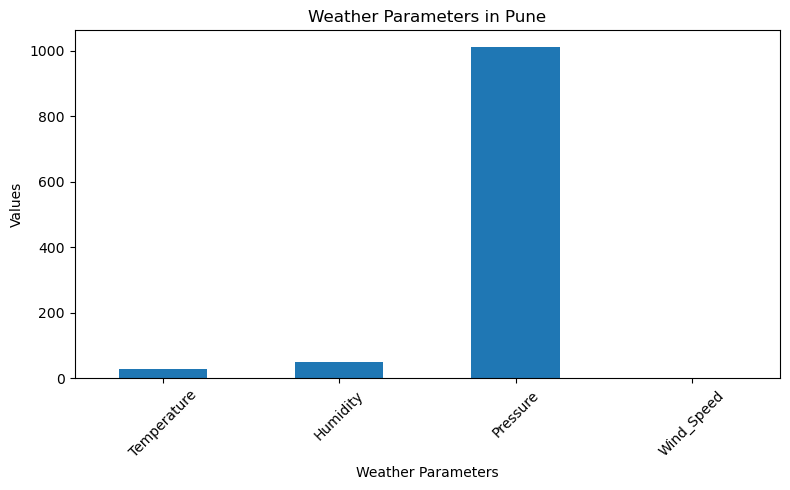

In [8]:
weather_values = weather_df[["Temperature", "Humidity", "Pressure", "Wind_Speed"]].iloc[0]

weather_values.plot(kind="bar", figsize=(8, 5))
plt.title("Weather Parameters in Pune")
plt.xlabel("Weather Parameters")
plt.ylabel("Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

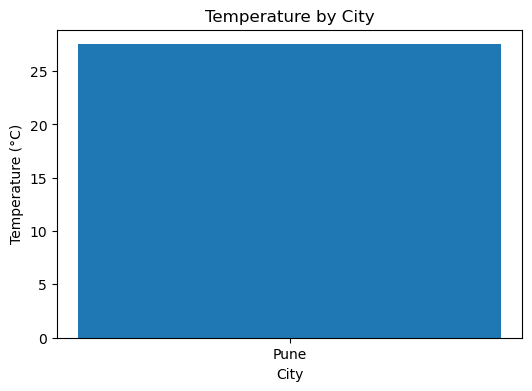

In [9]:
plt.figure(figsize=(6, 4))
plt.bar(weather_df["City"], weather_df["Temperature"])
plt.title("Temperature by City")
plt.xlabel("City")
plt.ylabel("Temperature (°C)")
plt.show()

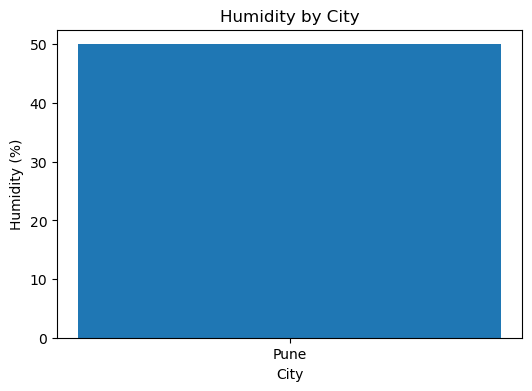

In [10]:
plt.figure(figsize=(6, 4))
plt.bar(weather_df["City"], weather_df["Humidity"])
plt.title("Humidity by City")
plt.xlabel("City")
plt.ylabel("Humidity (%)")
plt.show()

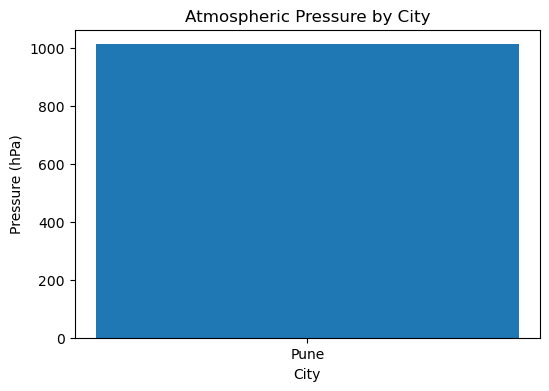

In [11]:
plt.figure(figsize=(6, 4))
plt.bar(weather_df["City"], weather_df["Pressure"])
plt.title("Atmospheric Pressure by City")
plt.xlabel("City")
plt.ylabel("Pressure (hPa)")
plt.show()

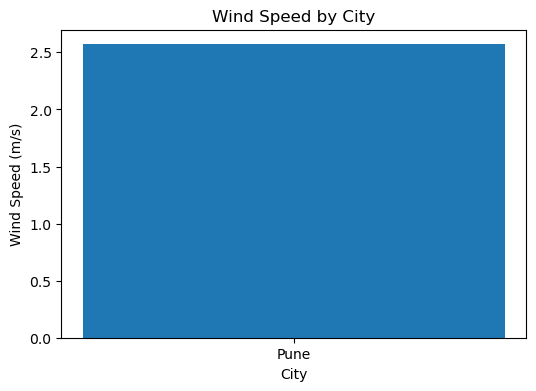

In [12]:
plt.figure(figsize=(6, 4))
plt.bar(weather_df["City"], weather_df["Wind_Speed"])
plt.title("Wind Speed by City")
plt.xlabel("City")
plt.ylabel("Wind Speed (m/s)")
plt.show()

In [13]:
weather_df.to_csv("weather_data.csv", index=False)

print("Weather data saved successfully!")

Weather data saved successfully!


In [14]:
saved_weather = pd.read_csv("weather_data.csv")

print("Dataset Shape:", saved_weather.shape)
saved_weather.head()

Dataset Shape: (1, 6)


,City,Temperature,Humidity,Pressure,Wind_Speed,Weather
0,Pune,27.5,50,1012,2.57,light rain
